# Lecture 14: Convex Functions and Optimization Algorithms
## Motivation
- Convex sets and functions. 
- Gradient Descent.
- Strongly convex functions.
- Newton's Method.

In [2]:
import numpy as np
import sklearn
import matplotlib.pyplot as plt

## 1. Convexity
### Convex sets
- A set $\Omega\subset\mathbb{R}^{d}$ is **convex** if, for all $x,y\in\Omega$ and all $t\in (0,1)$, we have that $tx + (1-t)y \in \Omega$. 
- **Interpretation** every line segment between points in $\Omega$ stays in $\Omega$. 

### Convex Functions
- A function $f(x): \mathbb{R}^{d}\to \mathbb{R}$ is convex if, for all $x,y\in\mathbb{R}^{d}$ and $t\in (0,1)$, we have that $f(tx + (1-t)y) \leq tf(x) + (1-t)f(y)$ 
- **Interpretation**
    - The secant line between any two points $x,y\in\mathbb{R}^{d}$ is **above the graph**.
- **Other Definitions:**
    - If $f(x)$ is differentiable then $f(y) \geq f(x) + \nabla f(x)^{\top}(\mathbf{y} - \mathbf{x})$
    - The tangent line at any $x\in\mathbb{R}^{d}$ is **below the graph**.
    - The **epi-graph** of $f(x)$ is a convex set.
    - If $f(x)$ is twice differentiable then $\nabla^{2}f(x) \geq 0$ 
    
![alt text](ConvexFunctions1.png)
![alt text](ConvexFunctions2.png)

*Pictures from https://www.math.ucla.edu/~wotaoyin/math273a/*

## 2. Examples of Convex Functions

1. Any quadratic function with + $x^2$ term, *e.g.* $f(x) = x^2 - 1$ <br/>
**Check:**
    - We'll show that $f(y) \geq f(x) + f^{'}(x)(y-x)$ equivalently $f(y) - f(x) - f^{'}(x)(y-x) \geq 0$
    - $f^{'}(x) = 2x$ 
    - $f(y) - f(x) - f^{'}(x)(y-x) = \left( y^2 - 1 \right) - \left(x^2 - 1\right) - \left(2x(y-x)\right)$ <br/>
      $ = \left( y^2 - 1 \right) - \left(x^2 - 1\right) - \left(2xy - 2x^2\right)$ <br/>
      $ = y^2 - 2xy + x^2 = (y-x)^2 \geq 0$
      
2. More generally, any quadratic function $f(\mathbf{x}) = \mathbf{x}^{\top}Q\mathbf{x} + \mathbf{b}^{\top}\mathbf{x}$ with $Q$ **positive semi-definite** 

3. Any norm is convex. <br/>
**Check:** <br/><br/>
$\|t\mathbf{x} + (1-t)\mathbf{y}\| \leq \|t\mathbf{x}\| + \|(1-t)\mathbf{y}\| = t\|\mathbf{x}\| + (1-t)\|\mathbf{y}\|$


3. Exponential functions $f(x) = e^{2x}$ <br/>
**Check**
    - We'll show that $f^{''}(x) \geq 0$ (note that $\nabla^{2} f(x) = f^{''}(x)$).
    - $f^{''}(x) = 4x^2 e^{2x} \geq 0$ 
    
4. Any composition $f(g(\mathbf{x}))$ where $f(\mathbf{x})$ is non-decreasing and $g(\mathbf{x})$ is convex *(homework)*

## 3. Optimization for convex functions

**Theorem:** Suppose that $f(\mathbf{x})$ is convex and $\mathbf{x}^{*}$ is a local minimizer. Then $\mathbf{x}^{*}$ is a global minimizer.

*proof.* 
- Local minimizer means $\nabla f(\mathbf{x}^{*}) = 0$.
- Let $\mathbf{y}\in\mathbb{R}^{d}$ be any other point.
- $f(\mathbf{y}) \geq f(\mathbf{x}^{*}) + \left(\nabla f(\mathbf{x}^{*})\right)^{\top}(\mathbf{y} - \mathbf{x}^{*}) = f(\mathbf{x}^{*})$

**Remark** Not claiming that $\mathbf{x}^{*}$ is the only minimizer.


## 4. Gradient Descent.

- Simple and powerful method for problem: $\text{minimize}_{\mathbf{x}\in\mathbb{R}^{d}}f(\mathbf{x})$
- **Algorithm:** $\mathbf{x}_{k+1} = \mathbf{x}_{k} - \alpha_{k}\nabla f(\mathbf{x}_k)$ 
- Stepsize: $\alpha_k = \alpha$ or can change. 
- *(Obviously)* requires access to gradient, $\nabla f(\mathbf{x})$. 
- **Intuition 1:** <br/>
    - $\nabla f(\mathbf{x})$ is direction of steepest increase, so $-\nabla f(\mathbf{x})$ is direction of steepest decrease.
    - Gradient descent takes steps in direction of steepest decrease.
    - Taylor expansion: $f(\mathbf{x}) = f(\mathbf{x}_k) + (\mathbf{x} - \mathbf{x}_k)^{\top}\nabla f(\mathbf{x}_k) + O((\mathbf{x} - \mathbf{x}_k)^{2})$
    - Take $\mathbf{x} = \mathbf{x}_{k+1} = \mathbf{x}_{k} - \alpha_{k}\nabla f(\mathbf{x}_k)$
    - Get: $f(\mathbf{x}_{k+1}) = f(\mathbf{x}_k) - \alpha \nabla f(\mathbf{x}_k)^{\top}\nabla f(\mathbf{x}_k) + O(\alpha^{2}) = f(\mathbf{x}_k) - \alpha \|\nabla f(\mathbf{x}_k)\|_{2}^{2} + O(\alpha^{2})$
    - So, guaranteed decrease for $\alpha$ **small enough**.
- **Intuition 2:** <br/>
    - Consider **linear approximation** with **proximal term** $L(\mathbf{x}) = f(\mathbf{x}_k) + (\mathbf{x} - \mathbf{x}_k)^{\top}\nabla f(\mathbf{x}_k) + \frac{1}{2\alpha_k}\|\mathbf{x} - \mathbf{x}_k \|_{2}^{2}$
    - *(Homework:)* check that $\mathbf{x}_{k+1} = \mathbf{x}_{k} - \alpha_{k}\nabla f(\mathbf{x}_k) = \text{argmin}_{\mathbf{x}\in\mathbb{R}^{d}}L(\mathbf{x})$ 
    - So, gradient descent minimizes a **local linear approximation** of $f(\mathbf{x})$. 

In [18]:
## A simple example of gradient descent for quadratic functions f(x) = (1/2)x^TQx
def QuadraticFunction(Q,x):
    val  = np.dot(np.dot(x.T,Q),x)/2
    return np.squeeze(val)

def GradientQuadraticFunction(Q,x):
    gradient = np.dot(Q,x)
    return np.squeeze(gradient)

In [19]:
def GradientDescent(Q,x_0, alpha):
    x_trajectory = np.zeros([2,100])
    f_trajectory = np.zeros([100,1])
    x = x_0
    for k in range(100):
        x_trajectory[:,k] = np.squeeze(x)
        f_trajectory[k] = QuadraticFunction(Q,x)
        x = x - alpha*GradientQuadraticFunction(Q,x)
    return x_trajectory, f_trajectory

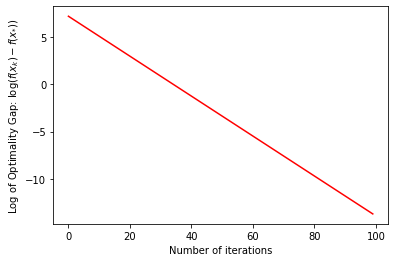

In [22]:
Q_1 = np.array([[1,0],[0,1]])
Q_2 = np.array([[5,0],[0,1]])
Q_3 = np.array([[100,0],[0,1]])
x_0 = np.array([10,50])
_,f_trajectory = GradientDescent(Q_1,x_0,0.1)
#_,f_trajectory_2 = GradientDescent(Q_2,x_0,0.1)
#_,f_trajectory_3 = GradientDescent(Q_3,x_0,0.1)
plt.plot(range(100),np.log(f_trajectory),'r') #,range(100),np.log(f_trajectory_2),'g',range(100),np.log(f_trajectory_3),'b')
plt.xlabel("Number of iterations")
plt.ylabel("Log of Optimality Gap: $\log(f(x_k) - f(x_{*}))$")
plt.show()

## 5. Gradient Descent for Convex Functions
- We say $f(x)$ is **Lipschitz Differentiable** if there exists an $L$ such that $\|\nabla f(\mathbf{x}) - \nabla f(\mathbf{y})\|_{2} \leq L\|\mathbf{x} - \mathbf{y}\|_{2}$ for all $\mathbf{x},\mathbf{y}$.<br/> <br/>

**Theorem** If $f(x)$ is L-Lipschitz Differentiable and convex, and $\alpha \leq 2/L$ then:
- $\|\mathbf{x}_{k+1} - \mathbf{x}_{*}\|_{2} \leq \|\mathbf{x}_{k} - \mathbf{x}_{*}\|_2$ for all $k$
- $f(\mathbf{x}_{k+1}) - f(\mathbf{x}_{*}) = O(2/k)$
- $\|\nabla f(\mathbf(x)_{k})\| = o(1/k)$

- For certain convex functions, a faster convergence rate is observed.

**Definition** If $f(\mathbf{x})$ is differentiable we say that $f(\mathbf{x})$ is $\mu$-strongly convex if:

$f(\mathbf{y}) \geq f(\mathbf{x}) + \nabla f(\mathbf{x})^{\top}(\mathbf{y} - \mathbf{x}) + \frac{\mu}{2} \|\mathbf{y} - \mathbf{x}\|_{2}^{2}$ 

**Interpretation**
- Take $\mathbf{x} = \mathbf{x}_{*}$ and $\mathbf{y}=  \mathbf{x}_{k}$, in which case $\nabla f(\mathbf{x}_{*}) = 0$. Then:

$f(\mathbf{x}_{k}) \geq f(\mathbf{x}_{*}) + \frac{\mu}{2} \|\mathbf{x}_{k} - \mathbf{x}\|_{2}^{2} \Rightarrow f(\mathbf{x}_{k}) - f(\mathbf{x}_{*}) \geq \frac{\mu}{2} \|\mathbf{x}_{k} - \mathbf{x}\|_{2}^{2}$ 

- Decrease is at least quadratic.

**Theorem** If $f(\mathbf{x})$ is L-Lipschitz Differentiable and $\mu$ strongly convex, and $\alpha < 1/\mu$ then:

$ f(\mathbf{x}_{k}) - f(\mathbf{x}_{*}) \leq O\left((1- \alpha\mu)^{k}\right)$

- Observe that if $f(\mathbf{x}_{k}) - f(\mathbf{x}_{*})  = Dc^{k}$ then $\log\left(f(\mathbf{x}_{k}) - f(\mathbf{x}_{*})\right) = \log(D) + k\log(c)$ is equation of a straight line.
- This is often called **linear convergence**.

**Remark** If $Q$ is **positive definite** then $f(\mathbf{x}) = \mathbf{x}^{\top}Q\mathbf{x} + \mathbf{b}^{\top}\mathbf{x} + \mathbf{c}$ is strongly convex.


## 6. Newton's Method

- Faster convergence, but larger per-iteration cost.
- **Notation:** $\mathbf{g}_{k} = \nabla f(\mathbf{x}_k)$ and $\mathbf{F}_k = \nabla^{2}f(\mathbf{x}_{k})$
- **Algorithm** $\mathbf{x}_{k+1} = \mathbf{x}_{k} - \mathbf{F}_{k}^{-1}\mathbf{g}_k$
- **Intuition:**
    - Construct a **quadratic approximation**:
    
    $q(\mathbf{x}) = f(\mathbf{x}_k) +(\mathbf{x} - \mathbf{x}_{k})^{\top}\mathbf{g}_k + \frac{1}{2}(\mathbf{x} - \mathbf{x}_{k})^{\top}\mathbf{F}_k(\mathbf{x} - \mathbf{x}_{k}) \approx f(\mathbf{x})$ 
    - **Claim:** $\mathbf{x}_{k+1} = \text{argmin}_{\mathbf{x}}q(\mathbf{x})$.
        - Can check that $\nabla q(\mathbf{x}) = \mathbf{g}_k + \mathbf{F}_k(\mathbf{x} - \mathbf{x}_{k})$
        - Find critical point: $0 = \nabla q(\mathbf{x}) = \mathbf{g}_k + \mathbf{F}_k(\mathbf{x} - \mathbf{x}_{k})$
        - Rearrange: $\mathbf{F}_k(\mathbf{x} - \mathbf{x}_{k}) = -\mathbf{g}_{k}$
        - $\Rightarrow \mathbf{x} - \mathbf{x}_{k} = -\mathbf{F}_k^{-1}\mathbf{g}_{k}$
        - $\Rightarrow \mathbf{x} = \mathbf{x}_{k}-\mathbf{F}_k^{-1}\mathbf{g}_{k}$
    - So Newton's method minimizes a local quadratic approximation of $f(\mathbf{x})$. 
- Analyzing Newton's Method is tricky, but: 


**Theorem** 
- Suppose that $f(x)$ is twice continuously differentiable.
- Let $\mathbf{x}_{*}$ be the minimizer, *i.e.* $\nabla f(\mathbf{x}_*) = 0$, and suppose $\nabla^{2}f(\mathbf{x}_{*})$ is pos. def.
- Then, if $\mathbf{x}_{0}$ is *sufficiently close* to $\mathbf{x}_{*}$:

\begin{align}\left\|\mathbf{x}_k - \mathbf{x}_{*}\right\|_2 \leq C\left\|\mathbf{x}_{k-1} - \mathbf{x}_{*}\right\|_{2}^{2}\end{align}

*This is called superlinear convergence*

- **Remark:** Optimality gaph $f(\mathbf{x}_k) - f(\mathbf{x})$ typically converges to $0$ quickly too.

- **Pro's:**
    - Fast rate of convergence.
    - (somewhat useful) Theoretical Guarantees.
- **Con's:**
    1. Need $\mathbf{x}_0$ to be close to $\mathbf{x}_{*}$, although usually this is less of an issue in practice.
    2. Requires access to $\nabla^{2}f(\mathbf{x}_k)$. Moreover, computing this can be expensive (requres computing $O(n^2)$ second partial derivatives). 
    3. Needs a positive definite Hessian. In particular $\mathbf{F}_k$ must be invertible.
    4. Newton's Method is not a descent method. That is, for some $k$ we may have $f(\mathbf{x}_{k+1}) > f(\mathbf{x}_k)$. </br>
    
    
- **Solution to 3:** The *Levenberg-Marquadt modification* Replace $\mathbf{F}_k$ with $\mathbf{F}_k + \gamma \mathbf{I}$. 
    - $\mathbf{F}_k$ always symmetric. Will be positive definite if all eigenvalues $> 0$.
    - Eigenvalues of $\mathbf{F}_k + \gamma \mathbf{I}$ are $\lambda_{i}(\mathbf{F}_k) + \gamma$.
    - For large enough $\gamma$, $\mathbf{F}_k + \gamma \mathbf{I}$is positive definite.
    
   
- **Solution to 4:** Use a step-size: $\mathbf{x}_{k+1} = \mathbf{x}_{k} - \alpha_k\mathbf{F}_{k}^{-1}\mathbf{g}_k$
    - **Theorem** for $\alpha_k$ small enough, $f(\mathbf{x}_{k+1}) < f(\mathbf{x}_k)$.
    
    
- **Solution to 2:** *Quasi-Newton* methods alleviate some of the burden of computing $\mathbf{F}_k$.


- **Solution to 1:** ?
    

In [23]:
def NewtonsMethod(Q,x_0, alpha):
    x_trajectory = np.zeros([2,100])
    f_trajectory = np.zeros([100,1])
    Q_inverse = np.linalg.inv(Q)
    x = x_0
    for k in range(100):
        x_trajectory[:,k] = np.squeeze(x)
        f_trajectory[k] = QuadraticFunction(Q,x)
        x = x - alpha*np.dot(Q_inverse,GradientQuadraticFunction(Q,x))
    return x_trajectory, f_trajectory

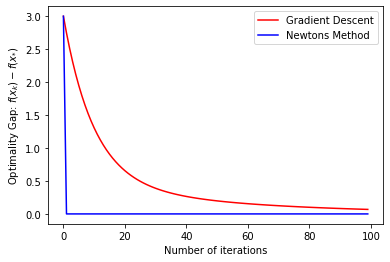

In [27]:
x_0 = np.array([1,1])
_,f_trajectory_GD = GradientDescent(Q_2,x_0,0.01)
_,f_trajectory_NM = NewtonsMethod(Q_2,x_0,0.5)
plt.plot(range(100),f_trajectory_GD,'r',range(100),f_trajectory_NM,'b')
plt.xlabel("Number of iterations")
plt.ylabel("Optimality Gap: $f(x_k) - f(x_{*})$")
plt.legend(('Gradient Descent', 'Newtons Method'))
plt.show()

## 7. Summary

- If $f(\mathbf{x})$ is convex then local min. = global min.
- Gradient Descent is a good and simple first order algorithm for solving $\text{minimize}_{\mathbf{x}\in\mathbb{R}^{d}} f(\mathbf{x})$. Guaranteed to converge at rate $O(1/k)$ when $f(\mathbf{x})$ is convex.
- Newton's Method is a second order algorithm, that can converge faster than GD, but is less robust (in theory and in practice).
- *Remark: both these methods can be applied to non-convex functions, and they frequently work. Have weaker theoretical guarantees though*
- **Further Resources:**
    - https://www.math.ucla.edu/~wotaoyin/math273a/
    - https://perso.telecom-paristech.fr/rgower/pdf/M2_statistique_optimisation/grad_conv.pdf
    - https://xingyuzhou.org/blog/notes/strong-convexity